# Phase 1 – Exploratory Data Analysis
## *Fair Price or Overpriced? Jordan's Used-Car Market and the Shift to Electric*

**Course:** Programming for Data Science (606315) – University of Petra  
**Team:** Team 7 – Adel Alawneh (202310707), Hashem Alawadi (202311241), Kareem Hamad (202310836)  
**Repository:** https://github.com/3adeljumah/prog-DS  
**Dataset:** JUCars-2024 – *A Dataset of Used Car Listings in Jordan* (Thalji, 2026), Mendeley Data, DOI [10.17632/ddcz486x5t.2](https://doi.org/10.17632/ddcz486x5t.2), licence **CC BY 4.0**.

### Goal of this notebook
Prove that the dataset is usable for the full project (Phase 2 enrichment → Phase 3 fair-price model and Django app) by:
1. Loading and inspecting the raw data.
2. Cleaning it: empty rows, duplicates, data types, missing values and outliers, with each rule justified.
3. Exploring it with filtering, GroupBy, **merge** (brand-origin table + US EPA fuel-economy data) and **pivot tables**.
4. Running NumPy calculations, such as robust z-scores, log-price depreciation rates and summary statistics.
5. Answering business questions with **8 visualisations**, each followed by an insight.

Advanced Python constructs from Weeks 1–2 are used: a decorator, a generator (`yield`), list/dictionary comprehensions, lambda functions, simple type hints and error handling (`try`/`except`).

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "data/"
RAW_URL = ("https://data.mendeley.com/public-files/datasets/ddcz486x5t/files/"
           "7a360fd6-9bb5-49fd-8f9a-c1f8053d067a/file_downloaded")
REFERENCE_YEAR = 2024
POWERTRAIN_ORDER = ["Gasoline", "Diesel", "Mild Hybrid", "Hybrid", "Plug-in - Hybrid", "Electric"]

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.1.1
NumPy version: 2.5.5


### Helper functions (advanced Python from Weeks 1–2)
* `cleaning_log` is a dictionary of lists. Every cleaning step adds one row to it (rows before / after).
* `log_step` is a **decorator**: it wraps each cleaning function, measures its time with `time.time()` and adds the result to `cleaning_log`.
* `load_csv` uses **error handling** (`try` / `except FileNotFoundError`): it reads the local file, and if the file is missing it downloads it from Mendeley.
* Functions have simple **type hints**, e.g. `df: pd.DataFrame -> pd.DataFrame`.

In [2]:
cleaning_log = {"step": [], "rows_before": [], "rows_after": [], "rows_removed": [], "ms": []}


def log_step(func):
    def wrapper(df):
        start = time.time()
        result = func(df)
        end = time.time()
        cleaning_log["step"].append(func.__name__)
        cleaning_log["rows_before"].append(len(df))
        cleaning_log["rows_after"].append(len(result))
        cleaning_log["rows_removed"].append(len(df) - len(result))
        cleaning_log["ms"].append(round((end - start) * 1000, 1))
        print(f"{func.__name__}: {len(df)} -> {len(result)} rows")
        return result
    return wrapper


def load_csv(name: str, url: str = None) -> pd.DataFrame:
    try:
        df = pd.read_csv(DATA_DIR + name)
    except FileNotFoundError:
        print(name, "not found - downloading from the source ...")
        df = pd.read_csv(url)
        df.to_csv(DATA_DIR + name, index=False)
    return df

## 1. Load & inspect the raw data

In [3]:
raw = load_csv("cars_raw.csv", url=RAW_URL)
print("Shape:", raw.shape)
raw.head()

Shape: (10921, 22)


,price_value_JOD,make,model,year,mileage_km,mileage_text,body_type,condition,transmission,fuel_type,...,interior_color,seats,city,feat_insurance,feat_carcustoms,feat_license,feat_paintcondition,feat_body_condition,feat_battery_capacity,feat_battery_range
0,13500.0,Honda,Accord,2017,154999.0,"150,000 - 159,999",Sedan,Used,Automatic,Hybrid,...,Black,5,Amman,Compulsory Insurance,With Customs,Licensed,Partially repainted,Good (body only has minor blemishes),NaN,NaN
1,22700.0,Mercedes Benz,C-Class,2016,134999.0,"130,000 - 139,999",Sedan,Used,Automatic,Plug-in - Hybrid,...,Black,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN
2,4700.0,Mazda,2,2013,104999.0,"100,000 - 109,999",HatchBack,Used,Automatic,Gasoline,...,Black,4,Amman,Compulsory Insurance,With Customs,Licensed,Total repaint,Good (body only has minor blemishes),NaN,NaN
3,12700.0,Hyundai,Ioniq,2019,94999.0,"90,000 - 99,999",Sedan,Used,Automatic,Hybrid,...,Grey,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN
4,13700.0,Toyota,Corolla,2021,34999.0,"30,000 - 39,999",Sedan,Used,Automatic,Gasoline,...,Beige,5,Amman,Compulsory Insurance,With Customs,Licensed,Original Paint,Excellent with no defects,NaN,NaN


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10921 entries, 0 to 10920
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_value_JOD        9739 non-null   float64
 1   make                   10285 non-null  str    
 2   model                  10204 non-null  str    
 3   year                   10284 non-null  str    
 4   mileage_km             8493 non-null   float64
 5   mileage_text           10285 non-null  str    
 6   body_type              10284 non-null  str    
 7   condition              10285 non-null  str    
 8   transmission           10282 non-null  str    
 9   fuel_type              10283 non-null  str    
 10  engine_type            10283 non-null  str    
 11  color                  10285 non-null  str    
 12  interior_color         10283 non-null  str    
 13  seats                  10284 non-null  str    
 14  city                   10285 non-null  str    
 15  feat_insuranc

In [5]:
raw.describe(include="all").T[["count", "unique", "top", "freq", "mean", "min", "max"]]

,count,unique,top,freq,mean,min,max
price_value_JOD,9739.0,NaN,NaN,NaN,15758.01263,550.0,7000000.0
make,10285,95,Hyundai,1312,NaN,NaN,NaN
model,10204,628,Avante,271,NaN,NaN,NaN
year,10284,56,2022,946,NaN,NaN,NaN
mileage_km,8493.0,NaN,NaN,NaN,78727.097021,0.0,194999.0
mileage_text,10285,23,"200,000",1792,NaN,NaN,NaN
body_type,10284,8,Sedan,4938,NaN,NaN,NaN
condition,10285,2,Used,9057,NaN,NaN,NaN
transmission,10282,2,Automatic,9125,NaN,NaN,NaN
fuel_type,10283,6,Gasoline,4521,NaN,NaN,NaN


In [6]:
load_csv("cars_dictionary.csv")[["Column Name", "Description", "Example / Possible Values"]]

,Column Name,Description,Example / Possible Values
0,price_value_JOD,Price of the car in Jordanian Dinar,"13500, 4700, 9400"
1,make,Car manufacturer / brand,"Honda, Toyota, BYD"
2,model,Car model,"Accord, Corolla, Seagull"
3,year,Year of manufacture,"2017, 2023, 2025"
4,mileage_km,Exact mileage in kilometers,"154999, 34999, 0 (new car)"
5,mileage_text,Mileage range (approximate),"150,000 - 159,999, 0 - 1,000"
6,body_type,Type of car body,"Sedan, SUV, HatchBack, Coupe, PickUp"
7,condition,Car condition,"Used, New"
8,transmission,Gearbox type,"Automatic, Manual"
9,fuel_type,Primary fuel type,"Gasoline, Hybrid, Electric, Diesel, Plug-in - ..."


### First observations
* `year` and `seats` are stored as **text**. `seats` contains the value `"More than 9"`.
* `mileage_km` is **binned**: each value is the upper edge of a 5,000 km bracket, so 24,999 means 20,000–24,999 km. The top bracket `"200,000"` (200,000 km or more) has **no numeric value**.
* `fuel_type` and `engine_type` look identical. We check this below.
* Some prices are clearly placeholders, such as 999,999 or 7,000,000 JOD.

In [7]:
missing = (raw.isnull().sum() / len(raw) * 100).sort_values(ascending=False).round(2)

fully_empty = (raw.isnull().sum(axis=1) == raw.shape[1]).sum()
print("Fully empty rows:", fully_empty)
print("Exact duplicate rows:", raw.duplicated().sum())

known = raw[raw["fuel_type"].notnull()]
same = (known["fuel_type"] == known["engine_type"]).mean()
print("fuel_type == engine_type on non-null rows:", round(same * 100, 1), "%")

pd.DataFrame({"missing_%": missing}).T

Fully empty rows: 636
Exact duplicate rows: 699
fuel_type == engine_type on non-null rows: 100.0 %


,feat_battery_capacity,feat_battery_range,mileage_km,feat_paintcondition,feat_body_condition,price_value_JOD,model,feat_insurance,feat_carcustoms,transmission,...,fuel_type,interior_color,body_type,seats,year,make,mileage_text,condition,color,city
missing_%,80.18,80.18,22.23,16.52,16.44,10.82,6.57,5.87,5.85,5.85,...,5.84,5.84,5.83,5.83,5.83,5.82,5.82,5.82,5.82,5.82


### Visualisation 1 – Where is data missing?

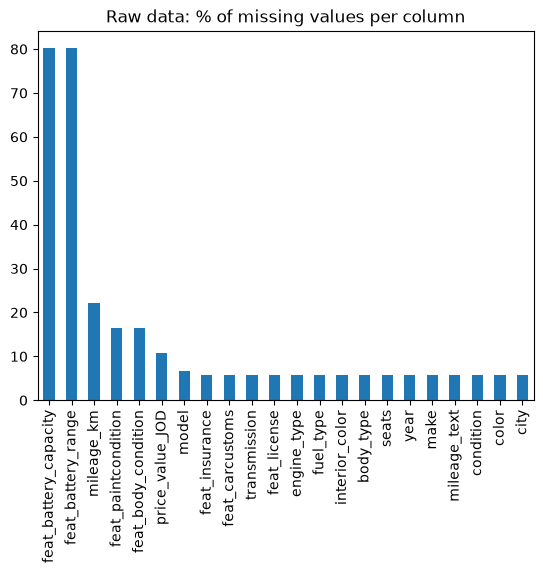

In [8]:
missing_cols = missing[missing > 0]
missing_cols.plot.bar(title="Raw data: % of missing values per column")
plt.show()

**Insight:** About 5.8% of rows (636) are **completely empty** scraping artefacts, which is why almost every column sits at the same ~6% line. The battery columns are 80% missing, but that is *structural*: they only apply to electric cars, so the gaps are not errors. Real gaps are in **mileage (22%)**, mostly the open-ended "200,000+ km" bracket, and **price (11%)**. Price is the target, so rows without it must be dropped.

## 2. Data cleaning
Each step is a small function wrapped with the `@log_step` decorator, so its effect is recorded in `cleaning_log`.

| Step | Rule | Justification |
|---|---|---|
| 1 | Drop fully-empty rows | Scraping artefacts with no information |
| 2 | Drop exact duplicates | The same advert scraped twice would bias counts and the model |
| 3 | Fix types | `year` → integer, `seats` → integer (`More than 9` → 10), drop redundant `engine_type` |
| 4 | Mileage | New cars → 0 km. The `200,000` bracket → 200,000 (lower bound) plus a flag. The remaining unknown mileage is imputed with the **median per vehicle age** |
| 5 | Missing price | Drop rows with no price, because price is the target variable |
| 6 | Hard price bounds | Keep 1,000–200,000 JOD. Values below 1,000 are instalment or down-payment adverts (for example a 2020 Tesla at 999 JOD). Values above 200,000 are typos or placeholders (999,999 or 7,000,000) |
| 7 | Down-payment adverts | Drop cars **≤ 10 years old priced below 2,500 JOD**. No car that young sells for that little in Jordan; sellers put the down payment in the price field (for example a 2024 BMW 4 Series at 1,000 JOD) |
| 8 | Model-relative outliers | Within each *make + model + 4-year model-year band* group with at least 5 adverts, compute a **modified z-score** (Iglewicz & Hoaglin, 1993) of log-price. Drop a row only if \|z\| > 3.5 **and** its price is more than 2× above or below the group median. The double condition protects tight groups with a tiny MAD. It catches down-payment adverts (for example a 2025 BYD Qin at 1,000 JOD) and typos (a 2016 Hyundai H1 at 99,999 JOD) that the global bounds keep |

In [9]:
@log_step
def drop_empty_rows(df: pd.DataFrame) -> pd.DataFrame:
    return df.dropna(how="all")


@log_step
def drop_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates()


@log_step
def fix_types(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["year"] = df["year"].replace("Older than 1970", np.nan).astype(float)
    df["model"] = df["model"].fillna("Other")
    df["seats"] = df["seats"].replace("More than 9", "10").astype(float)
    del df["engine_type"]
    new_names = {"price_value_JOD": "price_jod", "fuel_type": "powertrain"}
    df.columns = [new_names.get(col, col) for col in df.columns]
    text_cols = [col for col in df.columns if df[col].dtype == "object" or df[col].dtype == "str"]
    for col in text_cols:
        df[col] = df[col].str.strip()
    df["age"] = REFERENCE_YEAR - df["year"]
    df.loc[df["age"] < 0, "age"] = 0
    return df


@log_step
def fix_mileage(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["mileage_200k_plus"] = (df["mileage_text"] == "200,000").astype(int)
    df.loc[df["condition"] == "New", "mileage_km"] = 0
    df.loc[df["mileage_200k_plus"] == 1, "mileage_km"] = 200000
    df["mileage_imputed"] = df["mileage_km"].isnull().astype(int)
    median_by_age = df.groupby("age")["mileage_km"].transform("median")
    df["mileage_km"] = df["mileage_km"].fillna(median_by_age)
    return df


@log_step
def drop_missing_target(df: pd.DataFrame) -> pd.DataFrame:
    df = df.dropna(subset=["price_jod", "make", "year", "powertrain", "transmission"]).copy()
    df["year"] = df["year"].astype(int)
    df["age"] = df["age"].astype(int)
    df["seats"] = df["seats"].astype(int)
    return df


@log_step
def apply_price_bounds(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["price_jod"] >= 1000) & (df["price_jod"] <= 200000)]


@log_step
def drop_down_payment_ads(df: pd.DataFrame) -> pd.DataFrame:
    return df[~((df["age"] <= 10) & (df["price_jod"] < 2500))]


@log_step
def drop_relative_outliers(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["log_price"] = np.log(df["price_jod"])
    df["year_band"] = df["year"] // 4
    group_cols = ["make", "model", "year_band"]

    group_median = df.groupby(group_cols)["log_price"].transform("median")
    df["abs_dev"] = (df["log_price"] - group_median).abs()
    mad = df.groupby(group_cols)["abs_dev"].transform("median")
    group_size = df.groupby(group_cols)["log_price"].transform("count")

    z = np.where(mad == 0, 0.0, 0.6745 * (df["log_price"] - group_median) / mad)
    df["price_z"] = np.where(group_size >= 5, z, 0.0)

    is_outlier = (df["price_z"].abs() > 3.5) & (df["abs_dev"] > np.log(2))
    del df["year_band"]
    del df["abs_dev"]
    return df[~is_outlier]

In [10]:
df = drop_empty_rows(raw)
df = drop_duplicates(df)
df = fix_types(df)
df = fix_mileage(df)
df = drop_missing_target(df)
df = apply_price_bounds(df)
df = drop_down_payment_ads(df)
before_outliers = df.copy()
df = drop_relative_outliers(df)

pd.DataFrame(cleaning_log)

drop_empty_rows: 10921 -> 10285 rows
drop_duplicates: 10285 -> 10221 rows
fix_types: 10221 -> 10221 rows
fix_mileage: 10221 -> 10221 rows
drop_missing_target: 10221 -> 9703 rows
apply_price_bounds: 9703 -> 9504 rows
drop_down_payment_ads: 9504 -> 8958 rows
drop_relative_outliers: 8958 -> 8625 rows


,step,rows_before,rows_after,rows_removed,ms
0,drop_empty_rows,10921,10285,636,7.5
1,drop_duplicates,10285,10221,64,18.8
2,fix_types,10221,10221,0,19.4
3,fix_mileage,10221,10221,0,3.7
4,drop_missing_target,10221,9703,518,5.2
5,apply_price_bounds,9703,9504,199,1.7
6,drop_down_payment_ads,9504,8958,546,1.6
7,drop_relative_outliers,8958,8625,333,12.4


In [11]:
removed = before_outliers[~before_outliers.index.isin(df.index)]
removed = removed[["make", "model", "year", "condition", "price_jod"]]
print("Removed by the model-relative rule:", len(removed), "rows")
print("Share of them priced below 3,000 JOD:", round((removed["price_jod"] < 3000).mean() * 100), "%")

cheapest = removed.sort_values(by="price_jod", kind="mergesort").head(5)
dearest = removed.sort_values(by="price_jod", ascending=False, kind="mergesort").head(5)
pd.concat([cheapest, dearest])

Removed by the model-relative rule: 333 rows
Share of them priced below 3,000 JOD: 32 %


,make,model,year,condition,price_jod
1052,Hyundai,Avante,2002,Used,1000.0
1488,Toyota,Camry,2008,Used,1000.0
1869,Mitsubishi,L200,2011,Used,1000.0
2327,Hyundai,Porter,2012,Used,1000.0
3127,Toyota,Land Cruiser,2012,Used,1000.0
3878,Honda,Accord,2019,New,150111.0
9340,Land Rover,Range Rover,2022,Used,140000.0
9530,Land Rover,Range Rover,2023,Used,130000.0
2403,BMW,7 Series,2017,Used,122345.0
4215,Hyundai,Accent,2018,New,111411.0


In [12]:
battery_and_condition = ["feat_battery_capacity", "feat_battery_range",
                         "feat_paintcondition", "feat_body_condition"]
core_cols = [col for col in df.columns if col not in battery_and_condition]
quality = pd.DataFrame({
    "raw": [raw.shape[0], raw.shape[1], raw.isnull().sum().sum(), raw.duplicated().sum()],
    "clean": [df.shape[0], df.shape[1], df[core_cols].isnull().sum().sum(), df.duplicated().sum()],
}, index=["rows", "columns", "missing cells (core cols)", "duplicate rows"])

print(df.dtypes.value_counts())
quality

str        17
int64       5
float64     4
Name: count, dtype: int64


,raw,clean
rows,10921,8625
columns,22,26
missing cells (core cols),35001,0
duplicate rows,699,0


**Remaining missing values are expected and kept on purpose.** The battery columns only apply to EVs and plug-ins. Missing paint and body condition becomes an explicit `"Unknown"` category so the model can still use those adverts.

In [13]:
for col in ["feat_paintcondition", "feat_body_condition", "feat_battery_capacity", "feat_battery_range"]:
    df[col] = df[col].fillna("Unknown")

for col in ["feat_insurance", "feat_carcustoms", "feat_license"]:
    df[col] = df[col].fillna(df[col].mode()[0])

electrified = ["Electric", "Hybrid", "Plug-in - Hybrid", "Mild Hybrid"]
df["is_electrified"] = df["powertrain"].isin(electrified).astype(int)
print("Missing cells left:", df.isnull().sum().sum())

Missing cells left: 0


## 3. Merging external tables

### 3.1 Brand-origin table (`brand_origin.csv`)
The team built this small lookup table (95 brands → country of origin → region) to answer the question: *are Chinese brands driving Jordan's EV transition?*

In [14]:
origin = load_csv("brand_origin.csv")
rows_before = len(df)
df = pd.merge(df, origin, on="make", how="left")

print("Rows before:", rows_before, "| rows after:", len(df))
print("Makes without an origin:", df["origin_region"].isnull().sum())
pd.DataFrame({"listings": df["origin_region"].value_counts()})

Rows before: 8625 | rows after: 8625
Makes without an origin: 0


,listings
origin_region,
Japan,2288
Korea,2225
Europe,1863
North America,1132
China,1106
Other,11


### 3.2 US EPA fuel-economy data (`fuel_economy.csv`)
The [fueleconomy.gov](https://www.fueleconomy.gov/feg/download.shtml) dataset (U.S. DOE/EPA, public domain) has about 50k model-years with combined MPG and CO₂. We aggregate it to *make + base model + year* and **left-merge** it on normalised keys. A **generator** produces the normalised key variants.

In [15]:
epa = load_csv("fuel_economy.csv")
print("EPA shape:", epa.shape)

LETTERS_DIGITS = "abcdefghijklmnopqrstuvwxyz0123456789"


def normalise(text) -> str:
    result = ""
    for ch in str(text).lower():
        if ch in LETTERS_DIGITS:
            result = result + ch
    return result


def key_variants(make, model):
    if str(make).lower() == "mercedes benz":
        make = "mercedes-benz"
    mk = normalise(make)
    model = str(model)
    yield mk + "|" + normalise(model)
    yield mk + "|" + normalise(model.split()[0])
    yield mk + "|" + normalise(model.replace("-Class", ""))


epa["key"] = [normalise(m) + "|" + normalise(b) for m, b in zip(epa["make"], epa["baseModel"])]

epa_mean = epa.groupby(["key", "year"]).agg({"comb08": "mean", "co2TailpipeGpm": "mean"})
epa_agg = {"key": [], "year": [], "epa_mpg_comb": [], "epa_co2_gpm": []}
for name, row in epa_mean.iterrows():
    epa_agg["key"].append(name[0])
    epa_agg["year"].append(name[1])
    epa_agg["epa_mpg_comb"].append(row["comb08"])
    epa_agg["epa_co2_gpm"].append(row["co2TailpipeGpm"])
epa_agg = pd.DataFrame(epa_agg)
epa_keys = {key: True for key in epa_agg["key"]}


def find_epa_key(make, model):
    for key in key_variants(make, model):
        if key in epa_keys:
            return key
    return None


df["epa_key"] = [find_epa_key(m, mo) for m, mo in zip(df["make"], df["model"])]

df["year_f"] = df["year"].astype(float)
epa_agg["year_f"] = epa_agg["year"].astype(float)
rows_before = len(df)
df = pd.merge(df, epa_agg[["key", "year_f", "epa_mpg_comb", "epa_co2_gpm"]],
              left_on=["epa_key", "year_f"], right_on=["key", "year_f"], how="left")
del df["key"]
del df["year_f"]
print("Rows before:", rows_before, "| rows after:", len(df))

match_rate = df["epa_mpg_comb"].notnull().mean()
print("EPA match rate:", round(match_rate * 100, 1), "% of listings")
pd.DataFrame({"match_rate": df.groupby("origin_region")["epa_mpg_comb"].agg(lambda s: s.notnull().mean()).round(2)})

EPA shape: (50647, 11)


Rows before: 8625 | rows after: 8625
EPA match rate: 56.9 % of listings


,match_rate
origin_region,
China,0.00
Europe,0.55
Japan,0.72
Korea,0.59
North America,0.79
Other,0.00


About half of the adverts match. The ones that don't are mostly Chinese EVs and Korean domestic models that are never sold in the USA. In **Phase 2** this gap is filled with the NHTSA vPIC API and scraped EV specifications.

## 4. Filtering, GroupBy & pivot tables

In [16]:
young_used_ev = df.query('powertrain == "Electric" and condition == "Used" and age <= 3')
print("Young used EVs (<= 3 yrs):", len(young_used_ev), "listings")
print("Median price:", young_used_ev["price_jod"].median(), "JOD")
young_used_ev.groupby("make")["price_jod"].agg(["count", "median"]).sort_values(by="count", ascending=False).head(8)

Young used EVs (<= 3 yrs): 1078 listings
Median price: 18000.0 JOD


,count,median
make,,
BYD,215,14500.0
Volkswagen,176,21000.0
Neta,165,14250.0
Tesla,136,19500.0
Kia,61,20000.0
Changan,58,11450.0
Hyundai,43,20500.0
BMW,36,31250.0


In [17]:
groups = df.groupby("powertrain")
by_powertrain = pd.DataFrame({
    "listings": groups["price_jod"].count(),
    "median_price": groups["price_jod"].median(),
    "mean_age": groups["age"].mean(),
    "median_km": groups["mileage_km"].median(),
    "share_new": groups["condition"].agg(lambda s: (s == "New").mean()),
})
by_powertrain = by_powertrain.loc[POWERTRAIN_ORDER].round(2)
by_powertrain["share_%"] = (by_powertrain["listings"] / by_powertrain["listings"].sum() * 100).round(1)
by_powertrain

,listings,median_price,mean_age,median_km,share_new,share_%
powertrain,,,,,,
Gasoline,4074,6300.0,15.10,144999.0,0.02,47.2
Diesel,432,9600.0,12.96,134999.0,0.06,5.0
Mild Hybrid,152,37250.0,3.33,54999.0,0.07,1.8
Hybrid,1799,12700.0,7.15,114999.0,0.04,20.9
Plug-in - Hybrid,506,20900.0,2.07,0.0,0.53,5.9
Electric,1662,16200.0,2.62,44999.0,0.12,19.3


In [18]:
pivot_price = pd.pivot_table(df, values="price_jod", index="body_type",
                             columns="powertrain", aggfunc="median")
pivot_price = pivot_price[POWERTRAIN_ORDER]
top_bodies = df["body_type"].value_counts().index[:6]
pivot_price.loc[top_bodies].round(-2)

powertrain,Gasoline,Diesel,Mild Hybrid,Hybrid,Plug-in - Hybrid,Electric
body_type,,,,,,
Sedan,5400.0,3200.0,35800.0,11700.0,16200.0,16200.0
SUV,11000.0,13800.0,55000.0,16900.0,31900.0,18500.0
HatchBack,4500.0,2000.0,27400.0,10500.0,13900.0,12000.0
PickUp,15000.0,13900.0,5000.0,34700.0,NaN,49500.0
Coupe,6200.0,2300.0,34500.0,8700.0,NaN,17000.0
Bus - Van,5000.0,5500.0,NaN,NaN,NaN,10600.0


In [19]:
city_counts = df["city"].value_counts()
big_cities = city_counts[city_counts >= 50].index

city_pivot = pd.pivot_table(df[df["city"].isin(big_cities)], values="price_jod", index="city",
                            columns="powertrain", aggfunc="count", fill_value=0)
city_pivot = city_pivot.apply(lambda row: row / row.sum() * 100, axis=1)
city_pivot = city_pivot[POWERTRAIN_ORDER].round(1)
city_pivot["electrified"] = city_pivot[["Mild Hybrid", "Hybrid", "Plug-in - Hybrid", "Electric"]].sum(axis=1)
city_pivot.sort_values(by="electrified", ascending=False)

powertrain,Gasoline,Diesel,Mild Hybrid,Hybrid,Plug-in - Hybrid,Electric,electrified
city,,,,,,,
Zarqa,27.5,6.3,1.3,22.8,10.6,31.6,66.3
Irbid,44.2,4.7,0.9,24.8,4.6,20.7,51.0
Ramtha,42.1,10.5,1.8,28.1,3.5,14.0,47.4
Amman,49.8,4.2,2.2,20.2,5.7,18.0,46.1
Jerash,50.0,11.0,2.0,26.0,0.0,11.0,39.0
Salt,65.9,4.5,0.0,15.6,2.2,11.7,29.5
Mafraq,61.5,10.8,0.0,20.0,0.8,6.9,27.7
Al Karak,68.3,6.1,0.0,20.7,2.4,2.4,25.5
Aqaba,68.9,6.6,0.9,19.8,0.9,2.8,24.4


## 5. NumPy calculations

In [20]:
prices = df["price_jod"].values.astype(float)
log_p = np.log(prices)

summary = {
    "mean": np.mean(prices),
    "median": df["price_jod"].median(),
    "std": np.std(prices),
    "geometric_mean": np.exp(np.mean(log_p)),
    "min": df["price_jod"].min(),
    "max": df["price_jod"].max(),
    "skewness": np.mean((prices - np.mean(prices)) ** 3) / np.std(prices) ** 3,
    "skewness_log": np.mean((log_p - np.mean(log_p)) ** 3) / np.std(log_p) ** 3,
}
{k: round(float(v), 2) for k, v in summary.items()}

{'mean': 14114.52,
 'median': 11000.0,
 'std': 13221.13,
 'geometric_mean': 9963.37,
 'min': 1000.0,
 'max': 165000.0,
 'skewness': 3.21,
 'skewness_log': -0.31}

**Annual depreciation per powertrain.** For used cars aged 0–15, fit `log(price) = a + b·age` with `np.polyfit`. The annual value loss is then `1 − e^b`.

In [21]:
def annual_depreciation(sub: pd.DataFrame) -> float:
    x = sub["age"].values.astype(float)
    y = np.log(sub["price_jod"].values.astype(float))
    b = np.sum((x - np.mean(x)) * (y - np.mean(y))) / np.sum((x - np.mean(x)) ** 2)
    return 1 - np.exp(b)


used = df[(df["condition"] == "Used") & (df["age"] >= 0) & (df["age"] <= 15)]

depreciation = {pt: round(annual_depreciation(g) * 100, 1)
                for pt, g in used.groupby("powertrain") if len(g) >= 100}
pd.DataFrame({"annual_depreciation_%": pd.Series(depreciation)}).sort_values(by="annual_depreciation_%", ascending=False)

,annual_depreciation_%
Mild Hybrid,12.3
Electric,10.3
Gasoline,8.2
Diesel,7.7
Hybrid,7.6
Plug-in - Hybrid,5.9


In [22]:
num_cols = ["price_jod", "age", "mileage_km", "seats", "is_electrified"]
corr = df[num_cols].astype(float).corr().round(2)
corr

,price_jod,age,mileage_km,seats,is_electrified
price_jod,1.00,-0.52,-0.39,0.17,0.30
age,-0.52,1.00,0.52,-0.12,-0.58
mileage_km,-0.39,0.52,1.00,-0.03,-0.36
seats,0.17,-0.12,-0.03,1.00,0.06
is_electrified,0.30,-0.58,-0.36,0.06,1.00


## 6. Visual analysis

### Visualisation 2 – Price distribution: raw vs log scale

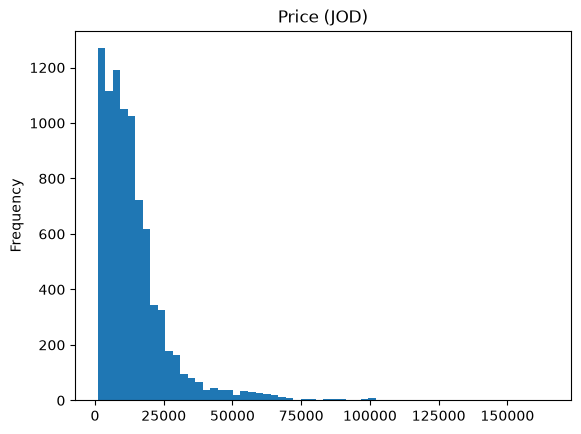

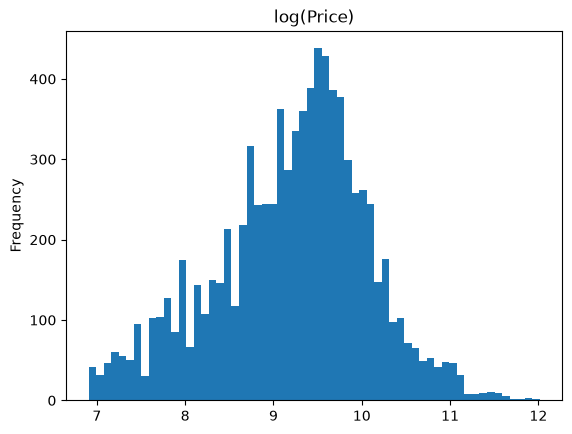

In [23]:
df["price_jod"].plot.hist(bins=60, title="Price (JOD)")
plt.show()

np.log(df["price_jod"]).plot.hist(bins=60, title="log(Price)")
plt.show()

**Insight:** Raw prices are strongly **right-skewed** (skewness ≈ 3.2; mean 14,115 JOD vs median 11,000 JOD). On a log scale the distribution is almost symmetric (skewness ≈ −0.3). → **The Phase 3 model will predict `log(price)`**, which stabilises the variance and stops a few luxury SUVs from dominating the error.

### Visualisation 3 – The electric transition: powertrain mix by model year

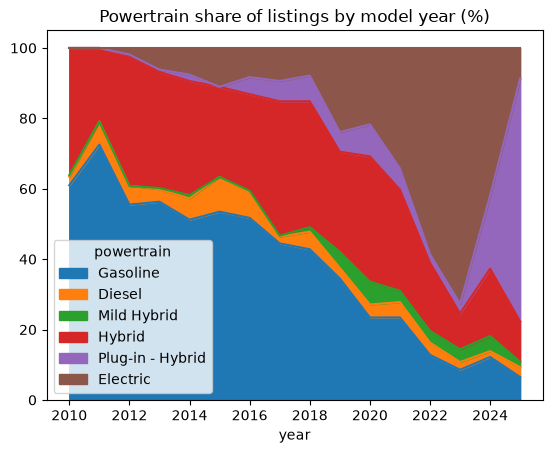

powertrain,Gasoline,Electric
year,,
2015,53.5,11.0
2018,42.8,7.8
2021,23.4,34.2
2023,8.6,72.7
2025,6.5,8.7


In [24]:
recent = df[(df["year"] >= 2010) & (df["year"] <= 2025)]
mix = pd.pivot_table(recent, values="price_jod", index="year", columns="powertrain",
                     aggfunc="count", fill_value=0)
mix = mix.apply(lambda row: row / row.sum() * 100, axis=1)
mix = mix[POWERTRAIN_ORDER]

mix.plot.area(title="Powertrain share of listings by model year (%)")
plt.show()

mix[["Gasoline", "Electric"]].loc[[2015, 2018, 2021, 2023, 2025]].round(1)

**Insight: this is the headline finding.** Among model-year 2015 cars, 53.5% of adverts are petrol and 11% fully electric. For model-year **2023** cars, **72.7% are fully electric and only 8.6% are petrol**. Jordan's young used-car stock has become mostly electric within about five model years. In 2024–2025 model years the mix swings towards **plug-in hybrids**: 211 of the 223 model-year-2025 PHEV adverts are *new* cars, and 212 of them are **BYD**. This may reflect a change in import or tax incentives, a hypothesis we will check in Phase 2 with scraped news and customs data.

### Visualisation 4 – Price by powertrain

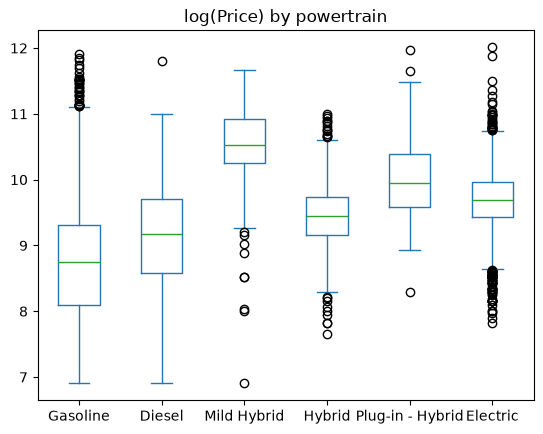

In [25]:
log_prices = pd.DataFrame({pt: np.log(df[df["powertrain"] == pt]["price_jod"]) for pt in POWERTRAIN_ORDER})
log_prices.plot.box(title="log(Price) by powertrain")
plt.show()

**Insight:** Powertrain alone separates price levels clearly. Medians: petrol **6,300 JOD**, hybrid **12,700**, electric **16,200**, plug-in hybrid **20,900** and mild hybrid **37,250**. Mild hybrids are mostly young Mercedes-Benz, Land Rover and BMW models (79% European), which makes them a luxury niche. Much of the EV "premium" is really an **age effect**: EVs average 2.6 years old vs 15.1 for petrol cars, and `age` correlates −0.58 with being electrified. → The model must learn price *conditional on age*. Comparing raw medians would mislead buyers.

### Visualisation 5 – Depreciation curves: do EVs lose value faster?

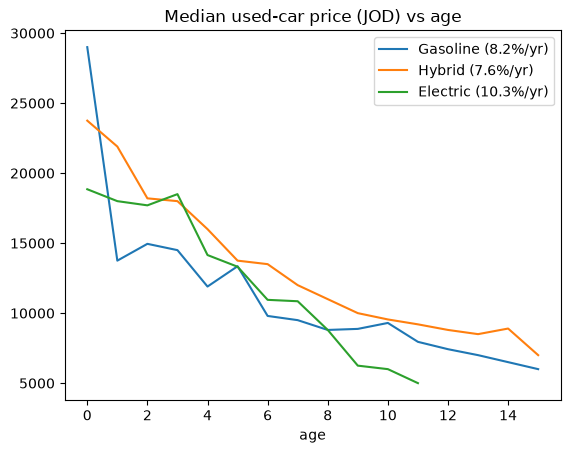

In [26]:
lines = {}
for pt in ["Gasoline", "Hybrid", "Electric"]:
    stats = used[used["powertrain"] == pt].groupby("age")["price_jod"].agg(["count", "median"])
    stats = stats[stats["count"] >= 15]
    lines[f"{pt} ({depreciation[pt]}%/yr)"] = stats["median"]

pd.DataFrame(lines).plot(title="Median used-car price (JOD) vs age")
plt.show()

**Insight:** Fitting `log(price) ~ age` with NumPy gives an annual value loss of **≈10.3% for EVs vs ≈8.2% for petrol cars and ≈7.6% for hybrids**. EVs hold their price for the first ~3 years (≈18,000 JOD) and then fall sharply. A 10-year-old EV is worth a median of **6,000 JOD vs 9,300 JOD** for a petrol car of the same age, probably because of battery-health worries and fast-improving new models. This is a direct, quantified answer for Jordanian buyers deciding between an EV and a petrol car.

### Visualisation 6 – Who sells Jordan's electric cars? (merge with origin table)

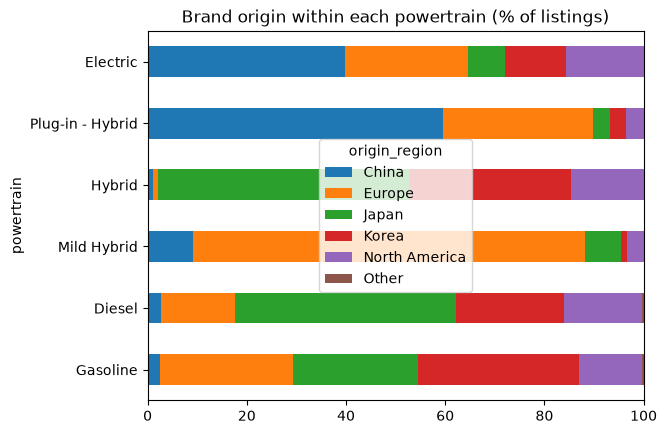

origin_region,China,Europe,Japan,Korea,North America,Other
powertrain,,,,,,
Gasoline,2.5,26.8,25.3,32.5,12.7,0.2
Diesel,2.8,14.8,44.7,21.8,15.7,0.2
Mild Hybrid,9.2,78.9,7.2,1.3,3.3,0.0
Hybrid,1.0,1.1,50.8,32.5,14.6,0.0
Plug-in - Hybrid,59.5,30.2,3.6,3.2,3.6,0.0
Electric,39.8,24.9,7.3,12.3,15.7,0.0


In [27]:
origin_mix = pd.pivot_table(df, values="price_jod", index="powertrain", columns="origin_region",
                            aggfunc="count", fill_value=0)
origin_mix = origin_mix.apply(lambda row: row / row.sum() * 100, axis=1)
origin_mix = origin_mix.loc[POWERTRAIN_ORDER]

origin_mix.plot.barh(stacked=True, title="Brand origin within each powertrain (% of listings)")
plt.show()

origin_mix.round(1)

**Insight (from the merge with `brand_origin.csv`):** Jordan's electric transition is **Chinese- and European-led**. Chinese brands (BYD, Neta, Changan…) make up **39.8% of EV adverts and 59.5% of plug-in-hybrid adverts**, against only 2.5% of petrol adverts. Volkswagen's ID series puts Europe at 24.9% of EVs. Conventional hybrids remain a **Japanese/Korean** stronghold (83%: Toyota, Hyundai, Kia). Brand origin is therefore a strong candidate feature for the price model.

### Visualisation 7 – Pivot heatmap: median price by body type × powertrain

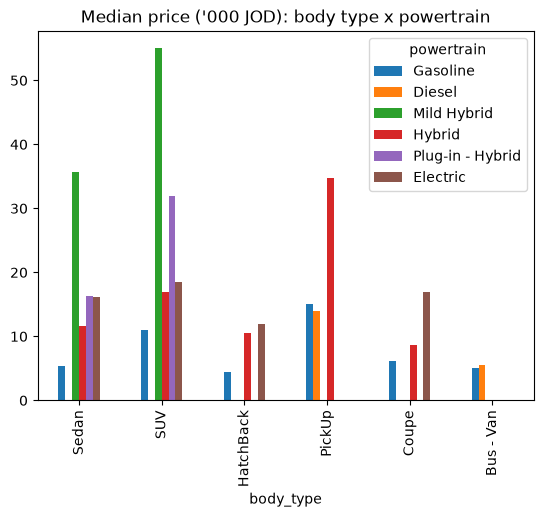

powertrain,Gasoline,Diesel,Mild Hybrid,Hybrid,Plug-in - Hybrid,Electric
body_type,,,,,,
Sedan,5.4,NaN,35.8,11.7,16.2,16.2
SUV,11.0,NaN,55.0,16.9,31.9,18.5
HatchBack,4.5,NaN,NaN,10.5,NaN,12.0
PickUp,15.0,13.9,NaN,34.7,NaN,NaN
Coupe,6.2,NaN,NaN,8.7,NaN,17.0
Bus - Van,5.0,5.5,NaN,NaN,NaN,NaN


In [28]:
counts = pd.pivot_table(df, values="price_jod", index="body_type", columns="powertrain",
                        aggfunc="count", fill_value=0)
counts = counts.loc[top_bodies, POWERTRAIN_ORDER]

table = pivot_price.loc[top_bodies] / 1000
for col in table:
    table.loc[counts[col] < 10, col] = np.nan

table.plot.bar(title="Median price ('000 JOD): body type x powertrain")
plt.show()

table.round(1)

**Insight (pivot table):** The electric premium depends on body type. For **sedans**, EVs (16,200) cost **3×** petrol sedans (5,400). For **SUVs** the gap is smaller (18,500 vs 11,000), because petrol SUVs include many young, large models. Mild-hybrid SUVs (55,000) are the luxury segment. Cells with fewer than 10 adverts are hidden so we don't draw conclusions from tiny samples. → The model needs **interaction effects** (body × powertrain), which favours tree-based models such as Random Forest or Gradient Boosting in Phase 3.

### Visualisation 8 – EV range vs price, and correlation of numeric drivers

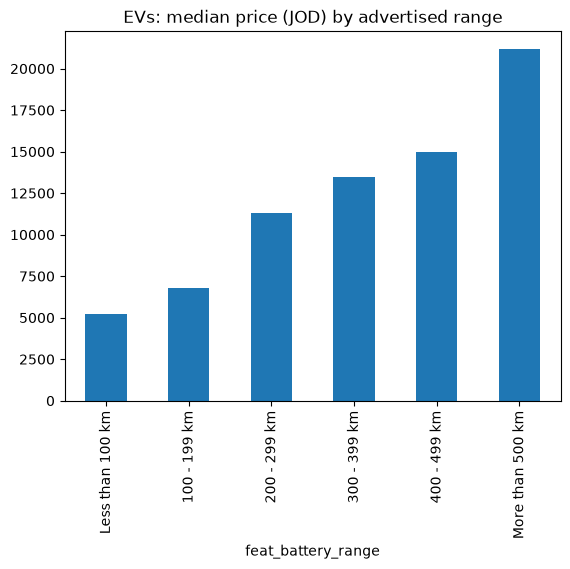

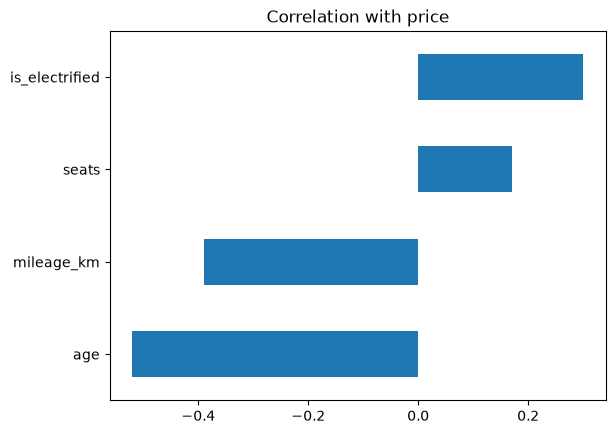

feat_battery_range
Less than 100 km     5250.0
100 - 199 km         6800.0
200 - 299 km        11300.0
300 - 399 km        13500.0
400 - 499 km        14950.0
More than 500 km    21200.0
Name: price_jod, dtype: float64

In [29]:
range_order = ["Less than 100 km", "100 - 199 km", "200 - 299 km",
               "300 - 399 km", "400 - 499 km", "More than 500 km"]
ev = df[(df["powertrain"] == "Electric") & (df["feat_battery_range"].isin(range_order))]
ev_by_range = ev.groupby("feat_battery_range")["price_jod"].median().loc[range_order]

ev_by_range.plot.bar(title="EVs: median price (JOD) by advertised range")
plt.show()

corr["price_jod"].drop("price_jod").plot.barh(title="Correlation with price")
plt.show()

ev_by_range

**Insight:** For EVs, **advertised range is the strongest value signal**: the median price rises steadily from 5,250 JOD (<100 km) to **21,200 JOD (>500 km)**, so it is worth enriching battery specs in Phase 2. In the correlation matrix (section 5), **age (−0.52)** and **mileage (−0.39)** are the main numeric price drivers. Age and mileage are themselves correlated (0.52), which a linear model must handle (multicollinearity).

## 7. Save the clean dataset for Phase 2

In [30]:
keep = [col for col in df.columns if col not in ["epa_key", "log_price", "price_z"]]
df[keep].to_csv(DATA_DIR + "cars_clean.csv", index=False)
print("Saved", DATA_DIR + "cars_clean.csv", df[keep].shape)

Saved data/cars_clean.csv (8625, 29)


## 8. Conclusions & readiness for Phases 2–3

| Check | Result |
|---|---|
| Size after cleaning | **8,625 adverts × 29 columns** (from 10,921 × 22 raw), all cleaning steps logged |
| Target quality | `price_jod` with no missing values, placeholders and down-payment adverts removed, log-transformed for modelling |
| Key drivers found | age, mileage, powertrain, body type, brand origin, EV range |
| Merges | Brand-origin table (100% match); US EPA fuel economy (56.9% match) |

**Key business findings**
1. **Electrified cars make up 47.8%** of all cleaned adverts. Among model-year-2023 cars, 72.7% are fully electric.
2. EVs lose value **faster** (≈10.3%/year vs 8.2% for petrol), so a fair-price tool matters most for buyers of used EVs.
3. At least **546 priced adverts (5.6%) quote a down payment instead of the full price**, for example a 2–3-year-old car listed at 1,000 JOD. Our Phase 3 app will flag such adverts automatically.

**Next steps**
* **Phase 2:** call the NHTSA vPIC and Recalls APIs in parallel (`ThreadPoolExecutor`, with a timing comparison) and the open.er-api.com exchange-rate API (JSON), and scrape EV battery and range specs from ev-database.org (BeautifulSoup, pagination, robots.txt respected) to fill the EPA gap for Chinese EVs.
* **Phase 3:** predict `log(price)` with a scikit-learn pipeline (Linear/Ridge vs Random Forest vs Gradient Boosting; metrics RMSE, MAE and R²). Serve it from a Django app with a market dashboard and a *"Is this car fairly priced?"* form and REST endpoint.

**AI-tool declaration:** The team used AI tools to assist in writing the code and the proposal, and all team members reviewed and understood the work.